# Customer Segmentation Using K-Means

## 1. Data Inspection

The goal of this project is to segment customers based on their purchasing
behaviour using K-Means clustering. First, we inspect the raw Online Retail
dataset to understand its structure and identify missing values, cancelled
transactions, invalid quantities, zero prices and duplicate records.

In [18]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Load the dataset
file_path = Path("week3/online-retail-dataset.csv")

if not file_path.exists():
    file_path = Path("online-retail-dataset.csv")

df = pd.read_csv(file_path)

# Basic dataset information
print("Dataset Shape:", df.shape)

print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Information:")
df.info()

# Missing CustomerID
missing_customers = df["CustomerID"].isna().sum()

# Cancelled invoices
cancelled = df["InvoiceNo"].astype(str).str.startswith("C").sum()

# Negative quantities
negative_quantity = (df["Quantity"] < 0).sum()

# Zero or negative prices
zero_prices = (df["UnitPrice"] <= 0).sum()

# Exact duplicate rows
duplicates = df.duplicated().sum()

# Largest quantity
largest_quantity = df["Quantity"].max()

# Display inspection results
print("\n--- DATA QUALITY REPORT ---")
print("Missing CustomerID:", missing_customers)
print("Cancelled Invoice Rows:", cancelled)
print("Negative Quantity Rows:", negative_quantity)
print("Zero or Negative Price Rows:", zero_prices)
print("Exact Duplicate Rows:", duplicates)
print("Largest Quantity:", largest_quantity)


Dataset Shape: (541909, 8)

First 5 Rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 33.1 MB

--- DATA QUALITY REPORT ---
Missing CustomerID: 135080
Cancelled Invoice Rows: 9288
Negative Quantity Rows: 10624
Zero or Negative Price Rows: 2517
Exact Duplicate Rows: 5268
Largest Quantity: 80995


### Observations

The dataset contains 541,909 rows and 8 columns. I noticed that
135080 CustomerID values are missing. There are also 9288 cancelled
invoice rows, 10624 rows with negative quantities, and 2517 rows
with zero or negative prices. Additionally, 5268 duplicate rows
were found. The largest recorded quantity is 80995.

These issues need to be investigated and cleaned before performing
customer segmentation.

## 2. Data Cleaning

The raw dataset contains missing customer IDs, cancelled invoices,
invalid quantities, zero or negative prices, and duplicate records.

I will remove these records to ensure that the customer segmentation
is based on valid purchasing transactions. I will also calculate
the total value of each transaction line.

In [19]:

# Keep the original dataset unchanged
clean_df = df.copy()

# Remove rows with missing CustomerID
clean_df = clean_df.dropna(subset=["CustomerID"])

# Remove cancelled invoices
clean_df = clean_df[
    ~clean_df["InvoiceNo"].astype(str).str.startswith("C")
]

# Remove invalid quantities
clean_df = clean_df[clean_df["Quantity"] > 0]

# Remove zero or negative prices
clean_df = clean_df[clean_df["UnitPrice"] > 0]

# Remove exact duplicate rows
clean_df = clean_df.drop_duplicates().copy()

# Calculate transaction value
clean_df["Value"] = clean_df["Quantity"] * clean_df["UnitPrice"]

# Calculate summary statistics
total_rows = len(clean_df)
total_customers = clean_df["CustomerID"].nunique()
total_revenue = clean_df["Value"].sum()

print("CLEANING SUMMARY")
print("-------------------------")
print("Rows remaining:", total_rows)
print("Unique customers:", total_customers)
print("Total revenue: £{:,.2f}".format(total_revenue))


CLEANING SUMMARY
-------------------------
Rows remaining: 392692
Unique customers: 4338
Total revenue: £8,887,208.89


### Cleaning Results

After cleaning the dataset, 392,692 valid transaction rows remain,
representing 4,338 unique customers. The total revenue is
£8,887,208.89.

Removing invalid transactions and duplicates helps ensure that
customer purchasing behaviour is measured using valid sales records.

## 3. Customer-Level Feature Engineering

I will group the cleaned transaction data by CustomerID to create
one row per customer.

Six features will be calculated to understand customer purchasing
behaviour: Recency, Frequency, Monetary, Average Basket Value,
Number of Products, and Tenure.

The reference date for calculating Recency and Tenure is
10 December 2011.

In [20]:

# Convert InvoiceDate to datetime
clean_df["InvoiceDate"] = pd.to_datetime(clean_df["InvoiceDate"])

# Reference date
reference_date = pd.Timestamp("2011-12-10")

# Create customer-level features
customers = clean_df.groupby("CustomerID").agg(
    last_purchase=("InvoiceDate", "max"),
    first_purchase=("InvoiceDate", "min"),
    frequency=("InvoiceNo", "nunique"),
    monetary=("Value", "sum"),
    n_products=("StockCode", "nunique")
)

# Calculate Recency and Tenure
customers["recency"] = (
    reference_date - customers["last_purchase"]
).dt.days

customers["tenure"] = (
    reference_date - customers["first_purchase"]
).dt.days

# Calculate Average Basket Value
customers["avg_basket"] = (
    customers["monetary"] / customers["frequency"]
)

# Keep only the six required features
customers = customers[
    ["recency", "frequency", "monetary",
     "avg_basket", "n_products", "tenure"]
]

# Display first five customers
display(customers.head())

print("\nCustomer-level dataset shape:", customers.shape)
print("Unique customers:", customers.index.nunique())


,recency,frequency,monetary,avg_basket,n_products,tenure
CustomerID,,,,,,
12346.0,325,1,77183.60,77183.600000,1,325
12347.0,2,7,4310.00,615.714286,103,367
12348.0,75,4,1797.24,449.310000,22,358
12349.0,18,1,1757.55,1757.550000,73,18
12350.0,310,1,334.40,334.400000,17,310



Customer-level dataset shape: (4338, 6)
Unique customers: 4338


In [21]:

# Calculate descriptive statistics
feature_summary = pd.DataFrame({
    "Median": customers.median(),
    "Maximum": customers.max(),
    "Skew": customers.skew()
})

display(feature_summary.round(2))


,Median,Maximum,Skew
recency,50.00,373.00,1.25
frequency,2.00,209.00,12.07
monetary,668.57,280206.02,19.34
avg_basket,291.94,84236.25,41.69
n_products,35.00,1787.00,6.92
tenure,248.00,373.00,-0.37


### Customer Feature Observations

The cleaned transaction data was converted into 4,338 customer
records with six purchasing behaviour features.

The median customer made 2 purchases, spent £668.57 in total,
and purchased 35 different products.

Most features have positive skewness. Average basket value has
the highest skewness of 41.69, while tenure has a negative
skewness of -0.37.

This shows that customer purchasing behaviour is unevenly
distributed, so log transformation is needed before clustering.

## 4. Data Preparation

The customer features have different distributions and several
features show high positive skewness.

I will apply np.log1p() to every feature with skewness above 1.
After transformation, I will check the skewness again.

Finally, I will use StandardScaler to bring all six features
onto a comparable scale before applying K-Means clustering.

In [22]:

# Identify columns with skewness greater than 1
columns_to_log = customers.skew()
columns_to_log = columns_to_log[columns_to_log > 1].index.tolist()

print("Columns selected for log transformation:")
print(columns_to_log)

# Create a copy of customer features
log_customers = customers.copy()

# Apply log1p transformation
for column in columns_to_log:
    log_customers[column] = np.log1p(log_customers[column])

# Display skewness after transformation
print("\nSkewness After Log Transformation:")
display(log_customers.skew().to_frame("Skew After Log").round(2))


Columns selected for log transformation:
['recency', 'frequency', 'monetary', 'avg_basket', 'n_products']

Skewness After Log Transformation:


,Skew After Log
recency,-0.47
frequency,1.21
monetary,0.40
avg_basket,0.24
n_products,-0.24
tenure,-0.37


### Log Transformation Observations

Log transformation reduced the skewness of all five selected
features. Monetary decreased from 19.34 to 0.40, while average
basket value decreased from 41.69 to 0.24.

Frequency still has a skewness of 1.21, but its distribution
became much less skewed. Tenure remained unchanged at -0.37
because its original skewness was below 1.

These transformations help reduce the influence of extreme
customer values before clustering.

In [23]:

from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Scale all six customer features
scaled_data = scaler.fit_transform(log_customers)

# Convert scaled data back into a DataFrame
scaled_customers = pd.DataFrame(
    scaled_data,
    columns=log_customers.columns,
    index=log_customers.index
)

# Display the first five scaled customers
display(scaled_customers.head())

print("\nScaled dataset shape:", scaled_customers.shape)

# Check mean and standard deviation
print("\nFeature Means:")
display(scaled_customers.mean().round(2))

print("\nFeature Standard Deviations:")
display(scaled_customers.std().round(2))


,recency,frequency,monetary,avg_basket,n_products,tenure
CustomerID,,,,,,
12346.0,1.435416,-0.955214,3.707716,7.522807,-2.526376,0.867007
12347.0,-1.953393,1.074425,1.414903,1.044160,0.965881,1.223420
12348.0,0.382865,0.386304,0.720024,0.622312,-0.367738,1.147046
12349.0,-0.619183,-0.955214,0.702287,2.449794,0.665088,-1.738199
12350.0,1.401368,-0.955214,-0.614514,0.227101,-0.584387,0.739717



Scaled dataset shape: (4338, 6)

Feature Means:


recency      -0.0
frequency    -0.0
monetary     -0.0
avg_basket    0.0
n_products    0.0
tenure        0.0
dtype: float64


Feature Standard Deviations:


recency       1.0
frequency     1.0
monetary      1.0
avg_basket    1.0
n_products    1.0
tenure        1.0
dtype: float64

### Scaling Observations

StandardScaler was applied successfully to all six customer
features. The transformed dataset contains 4,338 customers
and 6 features.

All feature means are approximately zero and their standard
deviations are 1.0. This ensures that no feature dominates
K-Means simply because of its numerical scale.

## 5. K-Means Clustering

K-Means is an unsupervised machine learning algorithm that groups
customers based on similar purchasing behaviour.

I will test different numbers of clusters (k = 2 to 8) and
evaluate them using inertia and silhouette scores to identify
a suitable number of customer segments.

In [24]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Store evaluation results
results = []

# Test different numbers of clusters
for k in range(2, 9):

    kmeans = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=42
    )

    labels = kmeans.fit_predict(scaled_customers)

    inertia = kmeans.inertia_
    silhouette = silhouette_score(scaled_customers, labels)

    results.append({
        "k": k,
        "inertia": inertia,
        "silhouette_score": silhouette
    })

# Create results table
results_df = pd.DataFrame(results)

display(results_df.round(4))


,k,inertia,silhouette_score
0,2,16718.5792,0.3156
1,3,13761.3714,0.2729
2,4,11810.5602,0.2360
3,5,10624.1732,0.2188
4,6,9670.1288,0.2214
5,7,8954.2537,0.2174
6,8,8396.1374,0.2117


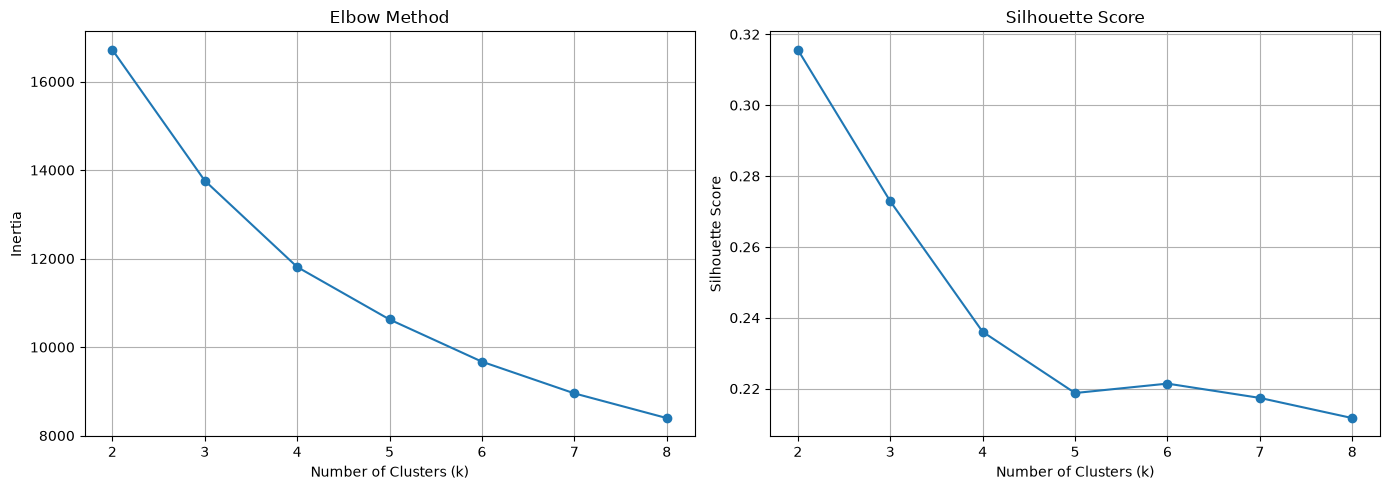

In [25]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Elbow Method
axes[0].plot(
    results_df["k"],
    results_df["inertia"],
    marker="o"
)

axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (k)")
axes[0].set_ylabel("Inertia")
axes[0].set_xticks(range(2, 9))
axes[0].grid(True)

# Silhouette Score
axes[1].plot(
    results_df["k"],
    results_df["silhouette_score"],
    marker="o"
)

axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of Clusters (k)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_xticks(range(2, 9))
axes[1].grid(True)

plt.tight_layout()
plt.show()


### K-Means Evaluation and Cluster Selection

I tested K-Means with values of k ranging from 2 to 8.

The inertia decreased from 16,718.58 at k=2 to 8,396.14
at k=8. The elbow plot suggests that the improvement
becomes smaller around four clusters.

The highest silhouette score was 0.3156 at k=2,
while k=4 achieved a score of 0.2360.

I selected k=4 as a balance between cluster separation
and business usefulness. Four segments can provide
more detailed customer groups for marketing decisions.
I will further examine their sizes and characteristics
to validate this choice.

In [26]:
display(results_df.round(4).to_string(index=False))

' k    inertia  silhouette_score\n 2 16718.5792            0.3156\n 3 13761.3714            0.2729\n 4 11810.5602            0.2360\n 5 10624.1732            0.2188\n 6  9670.1288            0.2214\n 7  8954.2537            0.2174\n 8  8396.1374            0.2117'

## 6. Scaling Experiment

I will compare the clustering results using the original
customer features without log transformation or scaling.

I will use the same number of clusters (k=4) to observe
how differences in feature magnitudes affect K-Means.

In [27]:

# Run K-Means on original, unscaled customer features
raw_kmeans = KMeans(
    n_clusters=4,
    n_init=10,
    random_state=42
)

raw_labels = raw_kmeans.fit_predict(customers)

# Count customers in each cluster
raw_cluster_sizes = pd.Series(raw_labels).value_counts().sort_index()

print("Cluster Sizes Without Scaling:")
print(raw_cluster_sizes)

print("\nTotal Customers:", raw_cluster_sizes.sum())


Cluster Sizes Without Scaling:
0    4300
1       3
2      30
3       5
Name: count, dtype: int64

Total Customers: 4338


### Scaling Experiment Observations

Without scaling, K-Means placed 4,300 customers in cluster 0,
while the remaining clusters contained only 3, 30, and 5 customers.

This shows that the clustering results are highly unbalanced
when the original features are used without scaling.

Scaling matters in K-Means because it uses distance, and
features with larger numerical ranges can dominate the results.

Scaling also matters in PCA because features with larger
variances can dominate the principal components.

In [28]:
## 7. Principal Component Analysis (PCA)

I will use PCA to reduce the six scaled customer features
to two principal components.

This will allow me to visualise the customer segments
in a two-dimensional plot.

I will also examine the explained variance and component
loadings to understand what each component represents.

SyntaxError: invalid syntax (581126703.py, line 3)

In [ ]:

from sklearn.decomposition import PCA

# Apply PCA to reduce six features to two components
pca = PCA(n_components=2)

pca_data = pca.fit_transform(scaled_customers)

# Create a DataFrame for PCA results
pca_df = pd.DataFrame(
    pca_data,
    columns=["PC1", "PC2"],
    index=scaled_customers.index
)

# Display explained variance
print("Explained Variance Ratio:")
print(pca.explained_variance_ratio_.round(4))

print("\nTotal Explained Variance:")
print(round(pca.explained_variance_ratio_.sum(), 4))


Explained Variance Ratio:
[0.5385 0.1888]

Total Explained Variance:
0.7274


In [ ]:

# Fit the final K-Means model
k = 4

final_kmeans = KMeans(
    n_clusters=k,
    n_init=10,
    random_state=42
)

# Assign customer segments
customers["Segment"] = final_kmeans.fit_predict(scaled_customers)

# Add segment labels to PCA data
pca_df["Segment"] = customers["Segment"]

print("Customer Segment Counts:")
print(customers["Segment"].value_counts().sort_index())

display(pca_df.head())


Customer Segment Counts:
Segment
0    1294
1    1038
2    1126
3     880
Name: count, dtype: int64


,PC1,PC2,Segment
CustomerID,,,
12346.0,2.436212,-1.282520,0
12347.0,3.003528,-0.126386,3
12348.0,0.755893,0.964588,0
12349.0,0.748246,-2.728639,2
12350.0,-1.273548,1.017597,1


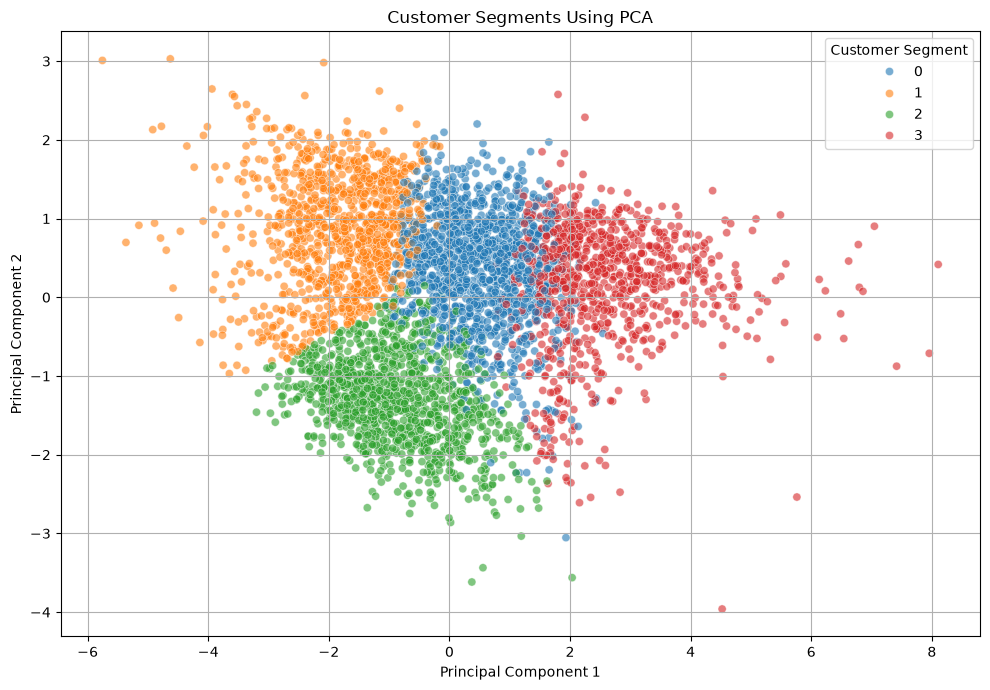

In [ ]:

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Segment",
    palette="tab10",
    alpha=0.6,
    s=35
)

plt.title("Customer Segments Using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Customer Segment")
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:

# Create PCA loading table
loadings = pd.DataFrame(
    pca.components_.T,
    index=scaled_customers.columns,
    columns=["PC1", "PC2"]
)

print("PCA Loadings:")
display(loadings.round(4))


PCA Loadings:


,PC1,PC2
recency,-0.3361,0.4493
frequency,0.4861,0.2038
monetary,0.5333,-0.0427
avg_basket,0.3109,-0.3216
n_products,0.4552,-0.0582
tenure,0.2500,0.8049


### PCA Observations

PCA reduced the six customer features to two principal components.
PC1 explains 53.85% of the variance, while PC2 explains 18.88%.
Together, they explain 72.74% of the total variance.

PC1 mainly represents customer purchasing value and activity,
with strong positive contributions from monetary, frequency
and number of products.

PC2 mainly represents customer history and purchasing lifecycle,
with tenure having the strongest contribution.

The PCA visualisation provides a two-dimensional view of the
four customer segments.

## 8. Business Reading: Customer Segment Analysis

I will analyse the four customer segments created by K-Means.

For each segment, I will calculate the number and percentage
of customers, percentage of total revenue, and median
recency, frequency and monetary value.

These statistics will help identify valuable customers,
regular buyers and customers who may need re-engagement.

In [ ]:

# Group customers by their assigned segment
segment_summary = customers.groupby("Segment").agg(
    customers=("recency", "size"),
    revenue=("monetary", "sum"),
    median_recency=("recency", "median"),
    median_frequency=("frequency", "median"),
    median_monetary=("monetary", "median")
)

# Calculate customer percentage
segment_summary["customer_pct"] = (
    segment_summary["customers"] / len(customers) * 100
)

# Calculate revenue percentage
segment_summary["revenue_pct"] = (
    segment_summary["revenue"] / customers["monetary"].sum() * 100
)

# Select and arrange required columns
segment_summary = segment_summary[
    [
        "customers",
        "customer_pct",
        "revenue_pct",
        "median_recency",
        "median_frequency",
        "median_monetary"
    ]
]

# Display the business summary
display(segment_summary.round(2))


,customers,customer_pct,revenue_pct,median_recency,median_frequency,median_monetary
Segment,,,,,,
0,1294,29.83,20.87,66.0,3.0,1032.58
1,1038,23.93,2.87,217.0,1.0,216.14
2,1126,25.96,6.91,32.0,1.0,408.85
3,880,20.29,69.35,9.0,9.0,3213.22


### Business Interpretation and Marketing Actions

**Segment 0 – Valuable but Cooling Customers:** These 1,294 customers contribute 20.87% of revenue. Their median spending is £1,032.58, but their median recency is 66 days. The marketing team should send personalised offers to encourage repeat purchases.

**Segment 1 – Inactive Low-Value Customers:** These 1,038 customers contribute only 2.87% of revenue. Their median recency is 217 days, and their median frequency is one invoice. The marketing team should try a low-cost reactivation campaign.

**Segment 2 – Recent Occasional Buyers:** These 1,126 customers contribute 6.91% of revenue. Their median recency is 32 days, but their median frequency is one invoice. The marketing team should encourage a second purchase through product recommendations and complementary offers.

**Segment 3 – VIP Loyal Customers:** These 880 customers generate 69.35% of total revenue. They have a median frequency of nine invoices, median spending of £3,213.22 and median recency of only nine days. The marketing team should focus on customer retention through VIP rewards and exclusive offers.

Overall, Segment 3 is the most valuable customer group and deserves particular attention because it generates the majority of the business's revenue.

## 9. Executive Summary

Segment 3 is the most valuable group, containing only 20.29%
of customers but generating 69.35% of total revenue.

I would contact Segment 3 first to retain these VIP customers
through exclusive rewards and personalised offers.

I would target Segment 0 next with reactivation campaigns
because these customers have valuable purchasing histories
but have become less active.